In [2]:
import os
import io
import time
import base64
from pathlib import Path
from getpass import getpass

import fitz
import pandas as pd

from PIL import Image
from IPython.display import display

from groq import Groq

from pinecone import Pinecone, ServerlessSpec

from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_groq import ChatGroq
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_pinecone import PineconeVectorStore

In [37]:
PDF_PATH = Path("data/Multimodal_RAG_LangChain_Pinecone_With_Examples_pptx.pdf")

# If you have the full NovaCore report, put it in the data/ folder and use this instead:
# PDF_PATH = Path("data/NovaCore_Multimodal_Company_Report_2026.pdf")

assert PDF_PATH.exists(), (
    f"PDF not found at {PDF_PATH}. Put your PDF inside the data/ folder "
    "and update PDF_PATH in this cell."
)

In [38]:
PDF_PATH

In [39]:
TEXT_MODEL = "openai/gpt-oss-20b"
VISION_MODEL = "qwen/qwen3.8-27b"
EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"

PINECONE_INDEX_NAME = "novacore-multimodal-rag"
PINECONE_NAMESPACE = "fy2026-demo"

IMAGE_DIR = Path("novacore_extracted_images")
IMAGE_DIR.mkdir(exist_ok=True)

print("PDF:", PDF_PATH)
print("Pinecone index:", PINECONE_INDEX_NAME)
print("Pinecone namespace:", PINECONE_NAMESPACE)

In [40]:
from dotenv import load_dotenv

# Reads GROQ_API_KEY and PINECONE_API_KEY from your local .env file.
# NEVER paste API keys directly into the notebook.
load_dotenv(override=True)

for key_name in ("GROQ_API_KEY", "PINECONE_API_KEY"):
    if not os.getenv(key_name):
        raise RuntimeError(
            f"{key_name} is missing. Copy .env.example to .env and add your keys."
        )

groq_client = Groq(api_key=os.environ["GROQ_API_KEY"])

text_llm = ChatGroq(
    model=TEXT_MODEL,
    temperature=0,
)

print("API clients are ready.")

API clients are ready.


In [42]:
def image_to_data_uri(image_path):
    image_path = Path(image_path)

    with Image.open(image_path) as img:
        img = img.convert("RGB")
        img.thumbnail((1600, 1600))

        buffer = io.BytesIO()
        img.save(buffer, format="JPEG", quality=85)

    encoded = base64.b64encode(buffer.getvalue()).decode("utf-8")
    return f"data:image/jpeg;base64,{encoded}"

In [43]:
def summarize_visual(image_path, page_number):
    image_data = image_to_data_uri(image_path)

    prompt = f"""
This visual was extracted from page {page_number} of the NovaCore FY2026 company report.

Describe the useful business information visible in the visual.

If it is a chart or graph:
- mention important values
- mention highest/lowest values
- mention the main trend

If it is a diagram:
- identify important components
- explain the flow or relationships

If it is a normal business image:
- describe the useful factual information

Keep the description concise and factual.
"""

    response = groq_client.chat.completions.create(
        model=VISION_MODEL,
        messages=[
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": prompt},
                    {
                        "type": "image_url",
                        "image_url": {"url": image_data},
                    },
                ],
            }
        ],
        temperature=0,
        max_completion_tokens=500,
    )

    return response.choices[0].message.content.strip()

In [44]:
def extract_multimodal_documents(pdf_path):
    pdf = fitz.open(str(pdf_path))

    documents = []
    extracted_xrefs = set()

    for page_index in range(len(pdf)):
        page = pdf[page_index]
        page_number = page_index + 1

        print(f"Processing page {page_number}...")

        # -------------------------------------------------
        # 1. TEXT
        # -------------------------------------------------
        text = page.get_text("text").strip()

        if text:
            documents.append(
                Document(
                    page_content=text,
                    metadata={
                        "page": page_number,
                        "modality": "text",
                        "source": pdf_path.name,
                    },
                )
            )

        # -------------------------------------------------
        # 2. TABLES
        # -------------------------------------------------
        try:
            tables = page.find_tables().tables

            for table_number, table in enumerate(tables, start=1):
                df = table.to_pandas()

                if not df.empty:
                    table_text = df.to_markdown(index=False)

                    documents.append(
                        Document(
                            page_content=table_text,
                            metadata={
                                "page": page_number,
                                "modality": "table",
                                "table_number": table_number,
                                "source": pdf_path.name,
                            },
                        )
                    )

        except Exception as error:
            print("Table extraction warning:", error)

        # -------------------------------------------------
        # 3. IMAGES / CHARTS / DIAGRAMS
        # -------------------------------------------------
        for image_number, image_info in enumerate(
            page.get_images(full=True),
            start=1,
        ):
            xref = image_info[0]

            # Do not process an identical embedded image twice.
            if xref in extracted_xrefs:
                continue

            extracted_xrefs.add(xref)

            image_data = pdf.extract_image(xref)
            image_bytes = image_data["image"]
            image_extension = image_data["ext"]

            image_path = (
                IMAGE_DIR
                / f"page_{page_number}_image_{image_number}.{image_extension}"
            )

            image_path.write_bytes(image_bytes)

            try:
                summary = summarize_visual(
                    image_path=image_path,
                    page_number=page_number,
                )

                documents.append(
                    Document(
                        page_content=summary,
                        metadata={
                            "page": page_number,
                            "modality": "visual",
                            "image_path": str(image_path),
                            "source": pdf_path.name,
                        },
                    )
                )

            except Exception as error:
                print(
                    f"Vision warning on page {page_number}:",
                    error,
                )

    pdf.close()
    return documents


documents = extract_multimodal_documents(PDF_PATH)

print()
print("Total LangChain documents:", len(documents))

Processing page 1...
Processing page 2...
Processing page 3...
Processing page 4...
Processing page 5...
Processing page 6...
Processing page 7...
Processing page 8...
Processing page 9...
Processing page 10...
Processing page 11...
Processing page 12...
Processing page 13...
Processing page 14...
Processing page 15...
Processing page 16...

Total LangChain documents: 39


In [45]:
documents

In [46]:
rows = []

for doc in documents:
    rows.append(
        {
            "page": doc.metadata["page"],
            "modality": doc.metadata["modality"],
            "preview": doc.page_content[:140].replace("\n", " "),
        }
    )

summary_df = pd.DataFrame(rows)

display(summary_df)

print("Documents by modality:")
display(summary_df["modality"].value_counts())

,page,modality,preview
0,1,text,"Multimodal RAG Chat with Text, Tables, Images ..."
1,1,visual,"Based on the visual provided, here is the desc..."
2,2,text,A real PDF is not just text Enterprise documen...
3,2,visual,"Based on the visual provided, here is the desc..."
4,2,visual,Based on the visual provided from the NovaCore...
5,3,text,Why traditional text RAG is not enough The cla...
6,3,visual,"Based on the visual provided, here is the desc..."
7,4,text,What is Multimodal RAG? RAG that retrieves and...
8,4,visual,"Based on the visual provided, here is the desc..."
9,5,text,Running example: NovaCore FY2026 report A fict...


Documents by modality:


modality
visual    22
text      16
table      1
Name: count, dtype: int64

In [47]:
embeddings = HuggingFaceEmbeddings(
    model_name=EMBEDDING_MODEL,
    encode_kwargs={"normalize_embeddings": True},
)

# Detect the exact vector dimension automatically.
EMBEDDING_DIMENSION = len(
    embeddings.embed_query("dimension check")
)

print("Embedding model:", EMBEDDING_MODEL)
print("Embedding dimension:", EMBEDDING_DIMENSION)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5420.63it/s]


Embedding model: sentence-transformers/all-MiniLM-L6-v2
Embedding dimension: 384


In [48]:
pc = Pinecone(
    api_key=os.environ["PINECONE_API_KEY"]
)

if not pc.has_index(PINECONE_INDEX_NAME):
    print("Creating Pinecone index...")

    pc.create_index(
        name=PINECONE_INDEX_NAME,
        dimension=EMBEDDING_DIMENSION,
        metric="cosine",
        spec=ServerlessSpec(
            cloud="aws",
            region="us-east-1",
        ),
    )

    # Wait until Pinecone reports that the index is ready.
    while not pc.describe_index(PINECONE_INDEX_NAME).status["ready"]:
        print("Waiting for Pinecone index...")
        time.sleep(2)

    print("Pinecone index created.")
else:
    print("Pinecone index already exists.")

index = pc.Index(PINECONE_INDEX_NAME)

print("Connected to:", PINECONE_INDEX_NAME)

Pinecone index already exists.
Connected to: novacore-multimodal-rag


In [49]:
try:
    index.delete(
        delete_all=True,
        namespace=PINECONE_NAMESPACE,
    )

    print("Cleared namespace:", PINECONE_NAMESPACE)

except Exception as error:
    print(
        "Namespace was probably empty. Continuing...",
        error,
    )

Namespace was probably empty. Continuing... (404)
Reason: Not Found
HTTP response headers: HTTPHeaderDict({'Date': 'Fri, 20 Nov 2026 19:25:46 GMT', 'Content-Type': 'application/json', 'Content-Length': '55', 'Connection': 'keep-alive', 'x-pinecone-request-latency-ms': '31', 'x-envoy-upstream-service-time': '31', 'x-pinecone-response-duration-ms': '32', 'server': 'envoy'})
HTTP response body: {"code":5,"message":"Namespace not found","details":[]}



In [50]:
vectorstore = PineconeVectorStore(
    index_name=PINECONE_INDEX_NAME,
    embedding=embeddings,
    namespace=PINECONE_NAMESPACE,
)

vectorstore.add_documents(documents)

print("Documents uploaded to Pinecone.")

Documents uploaded to Pinecone.


In [51]:
retriever = vectorstore.as_retriever(
    search_kwargs={"k": 5}
)

print("Retriever is ready.")

Retriever is ready.


In [52]:
query = "Which region had the highest revenue growth?"

retrieved_docs = retriever.invoke(query)

for i, doc in enumerate(retrieved_docs, start=1):
    print("=" * 80)
    print(
        f"Result {i} | "
        f"Page {doc.metadata.get('page')} | "
        f"Type: {doc.metadata.get('modality')}"
    )
    print(doc.page_content[:700])
    print()

Result 1 | Page 7.0 | Type: text
Example 2 — Table retrieval
Keep rows and columns together so relationships remain meaningful.
6
MODALITY EXAMPLE — TABLE
Region
2026 revenue
YoY growth
Customers
CSAT
Europe
$41.2M
31%
118
4.7/5
North America
$38.6M
27%
104
4.6/5
Asia Pacific
$34.9M
24%
96
4.8/5
Middle East
$17.3M
18%
51
4.5/5
Region
2026 revenue
YoY growth
Customers
CSAT
Q
Question A
Which region grew fastest?
Q
Question B
Which region had the highest CSAT?
QUESTION
Which region grew fastest?
ANSWER
Europe — 31% YoY. (Asia Pacific had the highest CSAT: 4.8/5.)

Result 2 | Page 8.0 | Type: visual
Based on the visual provided, here is the description of the business information:

**Chart Type:** Line Graph
**Title:** Quarterly Revenue Trend

**Key Data Points (Revenue in USD millions):**
*   **Q1 2025:** ~22.0 (Lowest value)
*   **Q2 2025:** ~23.5
*   **Q3 2025:** ~25.2
*   **Q4 2025:** ~27.2
*   **Q1 2026:** ~28.5
*   **Q2 2026:** ~31.5
*   **Q3 2026:** ~34.2
*   **Q4 2026:** ~37.5 (Hi

In [53]:
rag_prompt = ChatPromptTemplate.from_template(
    """
You are a helpful assistant answering questions about the
NovaCore Systems FY2026 company report.

Use ONLY the retrieved context below.

If the answer is not available in the context, say:
"I could not find that information in the report."

Mention page numbers when possible.

CONTEXT:
{context}

QUESTION:
{question}

ANSWER:
"""
)

text_rag_chain = (
    rag_prompt
    | text_llm
    | StrOutputParser()
)

print("Text RAG chain is ready.")

Text RAG chain is ready.


In [54]:
def format_context(retrieved_docs):
    parts = []

    for doc in retrieved_docs:
        page = doc.metadata.get("page")
        modality = doc.metadata.get("modality")

        parts.append(
            f"[Page {page} | {modality.upper()}]\n"
            f"{doc.page_content}"
        )

    return "\n\n".join(parts)

In [55]:
def answer_with_vision(question, context, image_paths):
    image_paths = image_paths[:3]

    content = [
        {
            "type": "text",
            "text": f"""
You are answering questions about the NovaCore Systems FY2026 report.

Use ONLY the retrieved context and the attached retrieved visuals.

RETRIEVED CONTEXT:
{context}

QUESTION:
{question}

Instructions:
- Answer factually.
- Use the attached visuals when relevant.
- Mention page numbers.
- If the information is missing, say you could not find it.
""",
        }
    ]

    for image_path in image_paths:
        content.append(
            {
                "type": "image_url",
                "image_url": {
                    "url": image_to_data_uri(image_path)
                },
            }
        )

    response = groq_client.chat.completions.create(
        model=VISION_MODEL,
        messages=[
            {
                "role": "user",
                "content": content,
            }
        ],
        temperature=0,
        max_completion_tokens=900,
    )

    return response.choices[0].message.content.strip()

In [58]:
# from pathlib import Path
# from PIL import Image
# from IPython.display import display


def ask_rag(question, show_sources=True, show_images=False):

    # 1. Retrieve from Pinecone
    retrieved_docs = retriever.invoke(question)

    # Limit retrieved docs
    retrieved_docs = retrieved_docs[:2]

    # 2. Create context
    context = format_context(retrieved_docs)

    # Limit context length to avoid token overflow
    context = context[:3000]

    # 3. Check whether Pinecone returned visuals
    image_paths = []

    for doc in retrieved_docs:
        if doc.metadata.get("modality") == "visual":

            image_path = doc.metadata.get("image_path")

            if image_path and Path(image_path).exists():
                image_paths.append(image_path)

    # Limit visuals to 1 image
    image_paths = image_paths[:1]

    print(f"Retrieved Docs: {len(retrieved_docs)}")
    print(f"Context Length: {len(context)}")
    print(f"Images Sent: {len(image_paths)}")

    # 4. Generate Answer
    try:

        if image_paths:

            answer = answer_with_vision(
                question=question,
                context=context,
                image_paths=image_paths,
            )

        else:

            answer = text_rag_chain.invoke(
                {
                    "context": context,
                    "question": question,
                }
            )

    except Exception as e:

        answer = f"Error generating answer: {e}"

    print("\nQUESTION:")
    print(question)

    print("\nANSWER:")
    print(answer)

    if show_sources:

        print("\nPINECONE RETRIEVED SOURCES:")

        for i, doc in enumerate(retrieved_docs, start=1):

            print(
                f"{i}. Page {doc.metadata.get('page')} "
                f"| {doc.metadata.get('modality')}"
            )

    if show_images and image_paths:

        print("\nRETRIEVED VISUALS:")

        for image_path in image_paths:
            display(Image.open(image_path))

    return {
        "answer": answer,
        "documents": retrieved_docs,
        "image_paths": image_paths,
    }


In [59]:
ask_rag(
    "What does NovaCore Systems do and where is the company headquartered?"
)

Retrieved Docs: 2
Context Length: 2483
Images Sent: 1

QUESTION:
What does NovaCore Systems do and where is the company headquartered?

ANSWER:
Based on the **Executive Overview** on **Page 1** of the report:

*   **What NovaCore Systems does:** The company specializes in **industrial AI gateways** for manufacturing, logistics, and energy companies. Their goal is to deliver predictive maintenance deployments in Europe, improving uptime and shortening post-deployment support response times.
*   **Headquarters:** The company is headquartered in **Singapore**.

PINECONE RETRIEVED SOURCES:
1. Page 5.0 | visual
2. Page 5.0 | visual


In [60]:
ask_rag(
    "Which region had the highest year-over-year revenue growth?"
)

Retrieved Docs: 2
Context Length: 1369
Images Sent: 1

QUESTION:
Which region had the highest year-over-year revenue growth?

ANSWER:
Based on the table provided on page 7.0, the region with the highest year-over-year revenue growth is **Europe**, with a growth rate of **31%**.

The attached visuals (Quarterly Revenue Trend) show overall company growth but do not provide a regional breakdown.

PINECONE RETRIEVED SOURCES:
1. Page 7.0 | text
2. Page 8.0 | visual


Retrieved Docs: 2
Context Length: 1306
Images Sent: 1

QUESTION:
According to the revenue graph, which quarter had the highest revenue?

ANSWER:
Based on the "Quarterly Revenue Trend" graph on page 8.0, the quarter with the highest revenue is **Q4 2026**. The graph shows a consistent upward trend, peaking at approximately **$37.5 million** in that quarter.

PINECONE RETRIEVED SOURCES:
1. Page 8.0 | visual
2. Page 8.0 | text

RETRIEVED VISUALS:


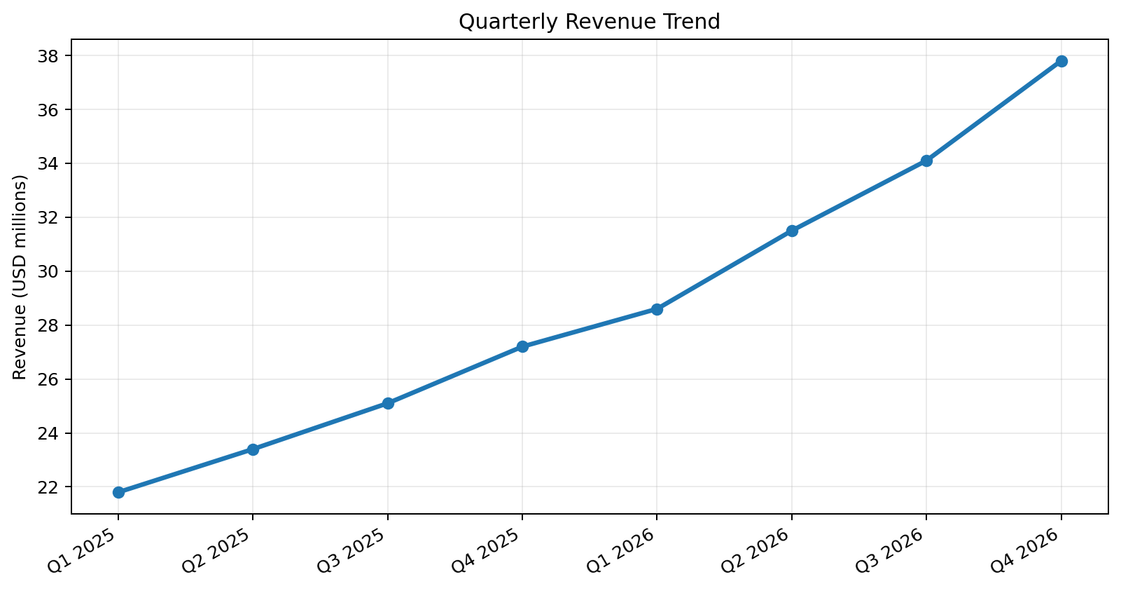

In [61]:
ask_rag(
    "According to the revenue graph, which quarter had the highest revenue?",
    show_images=True,
)

Retrieved Docs: 2
Context Length: 1491
Images Sent: 1

QUESTION:
According to the supply-chain diagram, what is the critical quality-control point?

ANSWER:
Based on the supply-chain diagram on page 9.0, the critical quality-control point is the **Quality Lab** located in **Singapore**. The diagram includes a specific callout box identifying the Quality Lab as the "Critical control point" and notes that every production batch must pass thermal, network, and firmware tests before export.

PINECONE RETRIEVED SOURCES:
1. Page 9.0 | visual
2. Page 9.0 | text

RETRIEVED VISUALS:


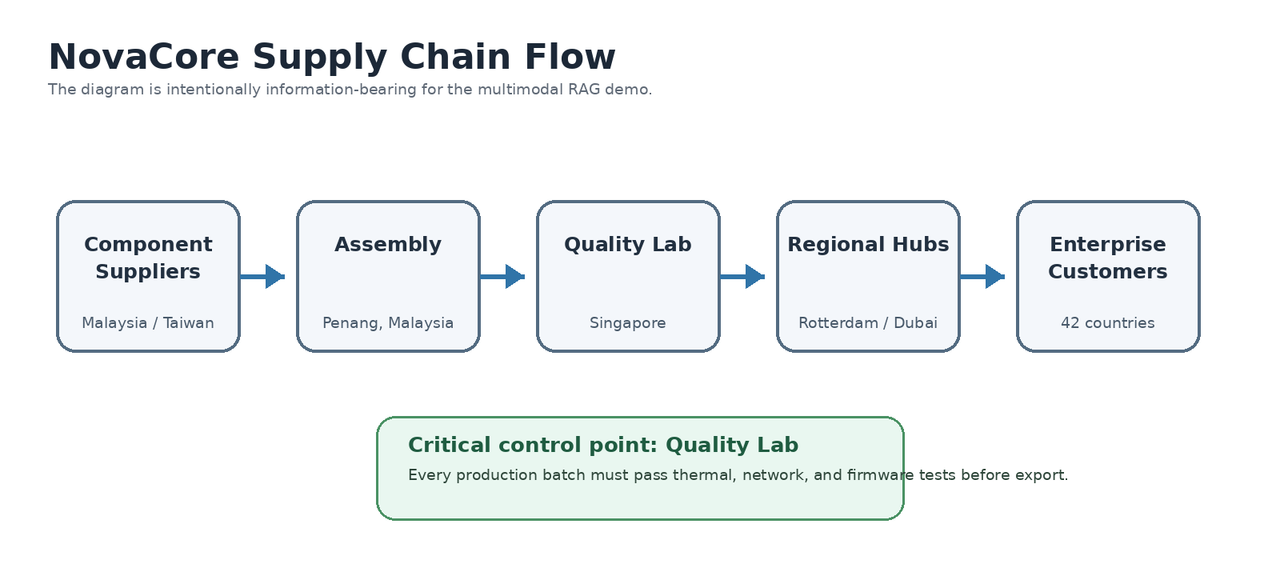

In [62]:
ask_rag(
    "According to the supply-chain diagram, what is the critical quality-control point?",
    show_images=True,
)

Retrieved Docs: 2
Context Length: 1449
Images Sent: 1

QUESTION:
How did average support resolution time change from January to August?

ANSWER:
Based on the NovaCore Systems FY2026 report (Page 14), the average support resolution time showed a consistent downward trend from January to August.

*   **January:** The average resolution time started at approximately **14.2 hours**.
*   **August:** It decreased to approximately **8.1 hours**.

This represents a reduction of about **43%** over the eight-month period, indicating a steady improvement in operational efficiency.

PINECONE RETRIEVED SOURCES:
1. Page 14.0 | visual
2. Page 14.0 | text

RETRIEVED VISUALS:


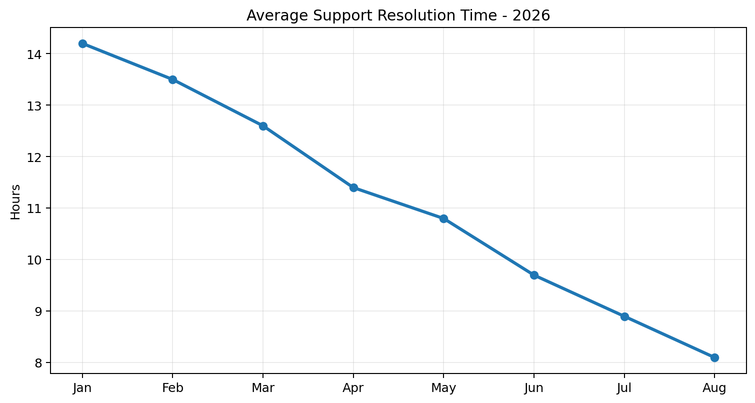

In [63]:
ask_rag(
    "How did average support resolution time change from January to August?",
    show_images=True,
)

In [64]:
ask_rag(
    """
Give me a short FY2026 performance summary.
Include:
1. total revenue,
2. fastest-growing region,
3. support-resolution improvement,
4. solar share at the Penang facility.
"""
)

Retrieved Docs: 2
Context Length: 3000
Images Sent: 1

QUESTION:

Give me a short FY2026 performance summary.
Include:
1. total revenue,
2. fastest-growing region,
3. support-resolution improvement,
4. solar share at the Penang facility.


ANSWER:
Based on the retrieved context and visuals, here is the FY2026 performance summary:

1.  **Total Revenue:** Total revenue for FY2026 was **$132.0M**, representing a 35.4% increase from the previous year (Page 2.0).
2.  **Fastest-growing region:** I could not find this information in the provided context.
3.  **Support-resolution improvement:** The company set a strategic priority to achieve an average resolution time of **< 4 hours** (Page 5.0).
4.  **Solar share at the Penang facility:** I could not find this information in the provided context.

PINECONE RETRIEVED SOURCES:
1. Page 2.0 | visual
2. Page 5.0 | visual
